In [10]:
!unzip archive.zip

Archive:  archive.zip
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep3_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep4_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep5_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep6_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep7_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep8_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep9_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_002_rep3_label1.npy  
  inflating: pr

In [11]:
path = "/content/processed_repetitions/2d_joints/Ex3"

In [12]:
!pip install optuna

In [13]:
!pip install pywt

ERROR: Could not find a version that satisfies the requirement pywt (from versions: none)
ERROR: No matching distribution found for pywt


In [14]:
import os
import re
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from collections import defaultdict
from dataclasses import dataclass

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, pairwise_distances)
from sklearn.model_selection import train_test_split
from scipy.signal import savgol_filter
import optuna
import pywt

In [15]:
SEED     = 42
N_TRIALS = 40
SAVE_PATH = "/content/kaggle"

def set_seed(s):
    np.random.seed(s)

set_seed(SEED)

In [16]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

### person-disjoint deterministic split (seed 42, stratified by flawed share)

In [17]:
def subject_split(records, test_size=0.2, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based."""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, stratify=strata, shuffle=True)
    except ValueError:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [18]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=7 persons, test=2 persons | train reps P=24, test reps P=9


In [19]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
g = lambda s, name: s[:, JN[name], :]

In [20]:
UPPER_BONES = [(0, 1), (1, 2), (2, 3), (3, 4),
               (6, 7), (7, 8), (8, 9),
               (11, 12), (12, 13), (13, 14),
               (0, 6), (0, 11), (1, 6), (1, 11)]

LEG_BONES = [(0, 16), (0, 21),
             (16, 17), (17, 18), (18, 19), (19, 20),
             (21, 22), (22, 23), (23, 24), (24, 25)]

HEAD_TIP  = [(4, 5), (9, 10), (14, 15)]
FULL_BONES = UPPER_BONES + LEG_BONES + HEAD_TIP

ANG  = slice(0, 8);   DANG = slice(8, 16)
BONE = slice(16, 44); POS  = slice(44, 56)
BLOCKS = {"ang": ANG, "dang": DANG, "bone": BONE, "pos": POS, "full": slice(0, 56)}

In [21]:
@dataclass
class ExConfig:
    n_frames: int = 90
    sgf_win: int = 11
    sgf_poly: int = 2

    use_angles: bool = True
    use_bone_vectors: bool = True
    use_arm_positions: bool = True
    use_angular_velocity: bool = True
    use_angular_accel: bool = False
    use_joint_speed: bool = False

    use_mirror_canonicalization: bool = True
    torso_eps: float = 1e-6

    angle_defs: tuple = (
        ("Neck", "LeftShoulder", "LeftArm"),
        ("Neck", "RightShoulder", "RightArm"),
        ("LeftShoulder", "LeftArm", "LeftForeArm"),
        ("RightShoulder", "RightArm", "RightForeArm"),
        ("LeftArm", "LeftForeArm", "LeftHand"),
        ("RightArm", "RightForeArm", "RightHand"),
        ("Hips", "Spine1", "Neck"),
    )
    arm_position_joints: tuple = ("LeftArm", "LeftForeArm", "LeftHand",
                                  "RightArm", "RightForeArm", "RightHand")

CFG = ExConfig()
N_FRAMES = CFG.n_frames

### normalizers (canonical -> spatial -> smooth -> resample)

In [22]:
def mirror_x(seq):
    """Mirror about the pelvis vertical axis. seq: (T,26,2)."""
    pelvis_x = seq[:, JN["Hips"], 0:1]
    out = seq.copy()
    out[:, :, 0] = 2.0 * pelvis_x - out[:, :, 0]
    return out

def canonicalize(seq, is_mirror_rep, cfg=CFG):
    if cfg.use_mirror_canonicalization and is_mirror_rep:
        return mirror_x(seq)
    return seq.copy()

In [23]:
def spatial_normalize(seq, cfg=CFG):
    out = seq.copy() - seq[:, JN["Hips"], :][:, None, :]
    a = seq[:, JN["Hips"], :]
    b = seq[:, JN["Spine"], :]
    tl = np.linalg.norm(b - a, axis=-1)
    tl = np.maximum(tl, cfg.torso_eps)
    return out / tl[:, None, None]

In [24]:
def smooth(seq, cfg=CFG):
    T = seq.shape[0]
    win = min(cfg.sgf_win if cfg.sgf_win % 2 == 1 else cfg.sgf_win + 1, (T // 2) * 2 + 1)
    if win < 5:
        return seq
    return np.stack([savgol_filter(seq[:, j, :], win, cfg.sgf_poly, axis=0)
                     for j in range(seq.shape[1])], axis=1)

In [25]:
def resample(seq, n=None):
    n = CFG.n_frames if n is None else n
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs = np.arange(T)
    xd = np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

### feature extractors

In [26]:
def angle_abc(a, b, c):
    ab, bc = a - b, c - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1, 1)))

def angle_channels(seq, cfg=CFG):
    feats, names = [], []
    for (p, v, d) in cfg.angle_defs:
        feats.append(angle_abc(g(seq, p), g(seq, v), g(seq, d)))
        names.append(f"ang_{v}")
    sh = g(seq, "RightShoulder") - g(seq, "LeftShoulder")
    feats.append(np.degrees(np.arctan2(sh[:, 1], sh[:, 0])))
    names.append("ang_shoulder_tilt")
    return np.stack(feats, axis=1), names

def bone_channels(seq, cfg=CFG):
    feats, names = [], []
    for (s, e) in UPPER_BONES:
        v = seq[:, e, :] - seq[:, s, :]
        feats.append(v[:, 0]); names.append(f"bone_{s}_{e}_x")
        feats.append(v[:, 1]); names.append(f"bone_{s}_{e}_y")
    return np.stack(feats, axis=1), names

def arm_position_channels(seq, cfg=CFG):
    feats, names = [], []
    for name in cfg.arm_position_joints:
        p = g(seq, name)
        feats.append(p[:, 0]); names.append(f"pos_{name}_x")
        feats.append(p[:, 1]); names.append(f"pos_{name}_y")
    return np.stack(feats, axis=1), names

def kinematic_channels(angles, seq, cfg=CFG):
    feats, names = [], []
    if cfg.use_angular_velocity:
        feats.append(np.gradient(angles, axis=0))
        names += [f"dang_{i}" for i in range(angles.shape[1])]
    if cfg.use_angular_accel:
        feats.append(np.gradient(angles, axis=0, edge_order=2)
                     if angles.shape[0] > 2 else np.zeros_like(angles))
        names += [f"d2ang_{i}" for i in range(angles.shape[1])]
    if cfg.use_joint_speed:
        v = np.gradient(seq, axis=0)
        speeds = np.linalg.norm(v, axis=-1)
        sel = [JN[n] for n in cfg.arm_position_joints]
        feats.append(speeds[:, sel])
        names += [f"speed_{cfg.arm_position_joints[i]}" for i in range(len(sel))]
    if not feats:
        return np.zeros((angles.shape[0], 0)), []
    return np.concatenate(feats, axis=1), names

### per-rep pipeline

In [27]:
def build_rep(coord, is_mirror_rep=False, cfg=CFG, return_template=True):
    x = np.asarray(coord, dtype=np.float64)
    x = canonicalize(x, is_mirror_rep, cfg)
    x = spatial_normalize(x, cfg)
    x_s = smooth(x, cfg)
    x_r = resample(x_s, cfg.n_frames)

    blocks, blk_names = [], []
    if cfg.use_angles:
        a, n = angle_channels(x_r, cfg)
        blocks.append(a); blk_names += n
        kin, kn = kinematic_channels(a, x_r, cfg)
        blocks.append(kin); blk_names += kn
    if cfg.use_bone_vectors:
        b, n = bone_channels(x_r, cfg)
        blocks.append(b); blk_names += n
    if cfg.use_arm_positions:
        p, n = arm_position_channels(x_r, cfg)
        blocks.append(p); blk_names += n
    if not blk_names:
        raise ValueError("no feature channels enabled in ExConfig")

    X = np.concatenate(blocks, axis=1)
    if not np.isfinite(X).all():
        raise ValueError("non-finite features produced (bad rep?)")

    out = {"X": X.astype(np.float32), "names": blk_names}
    if return_template:
        out["template"] = resample(x, cfg.n_frames).astype(np.float32)
    return out

In [28]:
class FeatureScaler:
    """Standardization fitted on TRAIN persons ONLY."""
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        std[std < 1e-8] = 1.0
        self.std_ = std
        return self

    def transform(self, X):
        return ((np.asarray(X, dtype=np.float64) - self.mean_) / self.std_).astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [29]:
# feature cache (built ONCE, not inside the Optuna loop)
def build_feature_cache(records, cfg=CFG):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr, r.get("is_mirror_rep", False), cfg)
        rec = dict(r)
        rec["X2d"]      = b["X"]
        rec["template"] = b["template"]
        out.append(rec)
    return out

feat_train = build_feature_cache(train)
feat_test  = build_feature_cache(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps "
      f"| per-rep shape={feat_train[0]['X2d'].shape}")

cached features: train=50 reps, test=13 reps | per-rep shape=(90, 56)


In [30]:
def std_rows(rows, scaler):
    """Standardize each cached rep (90,56) with the train-fitted scaler -> (N,90,56)."""
    return np.stack([scaler.transform(r["X2d"]) for r in rows]).astype(np.float32)

def _is_sup(spec):
    return bool(getattr(spec, "supervised", False))

class ArchSpec:
    """Per-architecture contract. Each arch = one subclass, nothing else to touch."""
    name = "arch"
    supervised = False
    def search_space(self, trial): raise NotImplementedError   # Optuna search space
    def train(self, X, y, p, seed): raise NotImplementedError  # X = packed
    def score(self, model, X, p): raise NotImplementedError    # (N,) higher = more flawed
    def pack(self, std_list, rows=None): raise NotImplementedError
    def embed(self, model, rows): raise NotImplementedError    # (N,latent) for the bank

def tpl_stack(rows):
    return np.stack([r["template"] for r in rows])            # (N,90,26,2), already normalized + resampled

def jn_take(names):
    """Only joints that exist in JN (defensive against name drift)."""
    return [JN[n] for n in names if n in JN]

### metrics (positive class = label 1 = PERFECT) + confusion + ROC

In [31]:
def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1); acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    fb = (1 + beta ** 2) * prec * rec / max(beta ** 2 * prec + rec, 1e-6)
    mcc = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) >= 2 else 0.0
    auroc = float(roc_auc_score(y_true, y_proba)) if len(np.unique(y_true)) >= 2 else 0.0
    return {"accuracy": acc, "balanced_acc": (rec + spec) / 2.0,
            "precision": prec, "recall": rec, "sensitivity": rec,
            "specificity": spec, "f1": f1, f"f{int(beta)}": fb,
            "mcc": mcc, "auroc": auroc,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print("                  Predicted PASS  Predicted FAIL")
    if cm.shape == (2, 2):
        tp, fn = cm[0, 0], cm[0, 1]
        fp, tn = cm[1, 0], cm[1, 1]
        print(f"  True PERFECT:  {tp:4d} ({tp / max(tp + fn, 1) * 100:5.1f}%)    "
              f"{fn:4d} ({fn / max(tp + fn, 1) * 100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp / max(tn + fp, 1) * 100:5.1f}%)    "
              f"{tn:4d} ({tn / max(tn + fp, 1) * 100:5.1f}%)")
    else:
        print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true)) < 2:
        return None
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auroc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, color="steelblue", lw=2.5, label=f"ROC (AUROC={auroc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("FPR (1-Specificity)", fontsize=9)
    ax.set_ylabel("TPR (Sensitivity)", fontsize=9)
    ax.set_title(f"{exercise_id} — ROC Curve", fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.4)
    fpath = os.path.join(save_path, f"{exercise_id}_roc.png")
    plt.savefig(fpath, dpi=100, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

### generic Optuna tuner + finalize + OOF-Platt (work for ANY spec)

In [32]:
def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    persons = sorted({r["person_id"] for r in rows})
    rng = np.random.RandomState(SEED)
    val_p = set(persons[i] for i in rng.permutation(len(persons))[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train reps={len(tr_r)} val reps={len(va_r)} "
          f"(person-disjoint: {len({r['person_id'] for r in tr_r})}/{len(val_p)} persons)")

    def objective(trial):
        p = spec.search_space(trial)
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in tr_r if r["label"] == 1], 0))
        # unsupervised specs train on CORRECT reps only (same filter as finalize/platt)
        tr_fit = tr_r if _is_sup(spec) else [f for f in tr_r if f["label"] == 1]
        Xt = spec.pack(std_rows(tr_fit, sc), tr_fit)
        vt = spec.pack(std_rows(va_r, sc), va_r)
        y_tr = np.array([r["label"] for r in tr_fit])
        model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
                 else spec.train(Xt, None, p, SEED))
        s_tr = spec.score(model, Xt, p); s_va = spec.score(model, vt, p)
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p["q"]) if _is_sup(spec) \
              else np.percentile(s_tr, p["q"])
        mcc = matthews_corrcoef(y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
              sampler=optuna.samplers.TPESampler(seed=SEED),
              pruner=optuna.pruners.MedianPruner())
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    # study.best_params contains ONLY suggested values — constants are dropped. Rebuild:
    full_p = spec.search_space(optuna.trial.FixedTrial(study.best_params))
    study.set_user_attr("best_full_params", full_p)
    return study

def finalize_for(spec, study, feats_train, feats_test):
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    Xc_rows = [f for f in feats_train if f["label"] == 1]
    scaler  = FeatureScaler().fit(np.concatenate([r["X2d"] for r in Xc_rows], 0))
    set_seed(SEED)
    tr_rows = feats_train if _is_sup(spec) else Xc_rows
    Xt = spec.pack(std_rows(tr_rows, scaler), tr_rows)
    y_tr = np.array([f["label"] for f in tr_rows])
    model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
             else spec.train(Xt, None, p, SEED))
    Xt_c = spec.pack(std_rows(Xc_rows, scaler), Xc_rows)
    errs_c = spec.score(model, Xt_c, p)
    thr = float(np.percentile(errs_c, p["q"]))
    print(f"provisional score threshold: {thr:.6f}")

    Xt_rows = list(feats_test)
    st = spec.score(model, spec.pack(std_rows(Xt_rows, scaler), Xt_rows), p)
    yt = np.array([r["label"] for r in Xt_rows])

    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, -st, spec.name)
    return dict(spec=spec, params=p, scaler=scaler, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=Xt_rows, study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    """Person-disjoint folds; OOF Platt fitted on log-scores, target = FLAWED."""
    p = dict(study.user_attrs.get("best_full_params") or study.best_params)
    persons = sorted({f["person_id"] for f in feat_train})
    assert len(persons) >= 2 * n_folds, "too few persons for OOF-Platt folds"
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(persons))
    folds = [set(np.array(persons)[c].tolist()) for c in np.array_split(perm, n_folds)]

    pl, ys = [], []
    for ps in folds:
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        sc = FeatureScaler().fit(np.concatenate(
            [r["X2d"] for r in tr_r if r["label"] == 1], 0))
        tr_fit = tr_r if _is_sup(spec) else [f for f in tr_r if f["label"] == 1]
        Xt = spec.pack(std_rows(tr_fit, sc), tr_fit)
        y_tr = np.array([r["label"] for r in tr_fit])
        model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
                 else spec.train(Xt, None, p, SEED))
        s = spec.score(model, spec.pack(std_rows(te_r, sc), te_r), p)
        pl += [np.log(np.clip(s, 1e-4, None))]
        ys += [f["label"] for f in te_r]
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)

    ys_f = 1.0 - ys                              # 1 = FLAWED (model score unit)
    lr2 = LogisticRegression(max_iter=1000).fit(pl.reshape(-1, 1), ys_f.astype(int))
    p_flawed = lr2.predict_proba(pl.reshape(-1, 1))[:, 1]
    auroc = roc_auc_score(ys_f, p_flawed)        # flawed-ranking AUROC
    slope = float(lr2.coef_[0][0])
    gate = "PASS" if (auroc > 0.5 and slope > 0) else "*** FAIL — do not ship verdicts ***"
    print(f"  Platt a={slope:.3f} b={lr2.intercept_[0]:.3f} | "
          f"OOF AUROC(flawed)={auroc:.3f} [{gate}] | "
          f"P(flawed): correct={p_flawed[ys_f == 0].mean():.3f} "
          f"flawed={p_flawed[ys_f == 1].mean():.3f}")
    return {"a": slope, "b": float(lr2.intercept_[0]), "oof_auroc": auroc,
            "oof_p": p_flawed, "oof_y": ys_f}   # OOF scores kept for the flag-rate cut

def platt_p_flawed(platt, scores):
    z = platt["a"] * np.log(np.clip(scores, 1e-4, None)) + platt["b"]
    return 1.0 / (1.0 + np.exp(-z))

### CorrectionBank + summary (embed_fn provided via spec)

In [33]:
JN_R = {v: k for k, v in JN.items()}

class CorrectionBank:
    def __init__(self, records, embed_fn):
        self.records = records
        self.embed_fn = embed_fn
        self.embs = embed_fn(records)
        self.by_person = {}
        for rec, e in zip(records, self.embs):
            self.by_person.setdefault(rec["person_id"], []).append((e, rec))

    def query(self, rec):
        q = self.embed_fn([rec])[0]
        pool = self.by_person.get(rec["person_id"]) or list(zip(self.embs, self.records))
        d = np.array([np.linalg.norm(q - e) for e, _ in pool])
        i = int(np.argmin(d))
        return pool[i][1], float(d[i])

    def correct(self, rec):
        ref, dist = self.query(rec)
        delta = ref["template"] - rec["template"]
        return {"ref": ref, "distance": dist, "delta": delta,
                "per_joint_disp": np.linalg.norm(delta, axis=-1).mean(0)}

def bank_summary(corr, top_k=4):
    """y grows DOWNWARD in the data: delta_y < 0 late in the rep -> 'raise it'."""
    top = np.argsort(-corr["per_joint_disp"])[:top_k]
    disp, delta = corr["per_joint_disp"], corr["delta"]
    F = delta.shape[0]
    imax = int(np.argmax(np.linalg.norm(delta, axis=-1)) // delta.shape[1])
    print(f"  reference distance (latent space): {corr['distance']:.4f}")
    print(f"  peak mismatch around frame {imax}/{F} "
          f"({'late' if imax > F / 2 else 'early' if imax < F / 4 else 'mid'} phase)")
    for j in top:
        print(f"   joint {j:>2} ({JN_R[j]:<13}) mean offset={disp[j]:.3f} torso-units")

### ghost overlay (full skeleton, shared window, y-down fixed)

In [34]:
def _draw_skel(ax, P, color, lw=1.2, label=None, ls="-"):
    ax.scatter(P[:, 0], P[:, 1], s=10, c=color, zorder=3, label=label)
    emphasized = set(UPPER_BONES)
    for s, e in FULL_BONES:
        if (s, e) in emphasized:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=lw, ls=ls, zorder=2)
        else:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=0.7, ls=ls, alpha=0.45, zorder=1)

def plot_ghost_overlay(rec, corr, sel=None, top_k=4, save_path=SAVE_PATH, prefix="Ex3"):
    rep, ref = rec["template"], corr["ref"]["template"]
    F = rep.shape[0]
    sel = sel or [0, F // 4, F // 2, 3 * F // 4, F - 1]
    top = np.argsort(-corr["per_joint_disp"])[:top_k]

    frames = np.concatenate([rep[sel], ref[sel]], axis=0)
    pad = 0.15
    x0, x1 = frames[:, :, 0].min(), frames[:, :, 0].max()
    y0, y1 = frames[:, :, 1].min(), frames[:, :, 1].max()
    xr, yr = (x1 - x0) or 1.0, (y1 - y0) or 1.0
    xlim, ylim = (x0 - pad * xr, x1 + pad * xr), (y0 - pad * yr, y1 + pad * yr)

    fig, axes = plt.subplots(1, len(sel), figsize=(3.1 * len(sel), 4.2))
    for ax, t in zip(np.atleast_1d(axes), sel):
        _draw_skel(ax, ref[t], "0.45", ls=":", label="ghost (correct ref)" if t == sel[0] else None)
        _draw_skel(ax, rep[t], "steelblue", label="performed rep" if t == sel[0] else None)
        for j in top:
            ax.annotate("", xy=ref[t, j], xytext=rep[t, j],
                        arrowprops=dict(arrowstyle="->", lw=1.4, color="crimson"))
        ax.set_xlim(*xlim)
        ax.set_ylim(ylim[1], ylim[0])     # y grows DOWNWARD in the data
        ax.set_aspect("equal")            # shared honest scale for all panels
        ax.set_title(f"frame {t}", fontsize=9); ax.axis("off")
    axes = np.atleast_1d(axes)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"{prefix} ghost overlay — {rec['person_id']} rep{rec['rep']} "
                 f"| latent dist={corr['distance']:.3f}", fontsize=10)
    fpath = os.path.join(save_path, f"{prefix}_ghost_{rec['person_id']}_rep{rec['rep']}.png")
    plt.savefig(fpath, dpi=110, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

In [35]:
BUNDLES = {}             # registry: every run lands here; summary cell at the bottom

def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2,
                   show_bank=True, ex_name=None, flag_rate=0.30):
    ex = ex_name or spec.name
    print(f"\n======== {ex} ========")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.user_attrs.get("best_full_params", study.best_params))

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)
    p_flawed = platt_p_flawed(platt, best["scores"])
    y_pred_platt = (p_flawed < 0.5).astype(int)          # PASS when P(flawed) < 0.5
    m = compute_all_metrics(best["y"], y_pred_platt, 1.0 - p_flawed)  # proba for PERFECT
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], y_pred_platt, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")

    # ---- FLOOD-PROOF CUT: threshold = OOF flag-rate quantile, NOT the fixed 0.5 ----
    thr_flag = float(np.percentile(platt["oof_p"], 100.0 * (1.0 - flag_rate)))
    pred_pass = (p_flawed < thr_flag).astype(int)       # 1 = PASS
    m_flag = compute_all_metrics(best["y"], pred_pass, 1.0 - p_flawed)
    print(f"\n  [{ex}] OOF-quantile cut report (flag_rate={flag_rate:.0%}, t={thr_flag:.3f})")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v)
           for k, v in m_flag.items()})
    print_confusion_matrix(best["y"], pred_pass, f"{ex}-OOFcut")
    best["oof_cut"] = {"t": thr_flag, "flag_rate": flag_rate, "metrics": m_flag}

    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)
    BUNDLES[ex] = best

    if show_bank:
        model = best["model"]
        bank = CorrectionBank([f for f in feat_train if f["label"] == 1],
                              embed_fn=lambda rows: spec.embed(model, rows))
        i = int(np.argmax(p_flawed))
        rec = best["rows"][i]
        print(f"worst test rep: {rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_flawed={p_flawed[i]:.3f}")
        corr = bank.correct(rec)
        bank_summary(corr)
        plot_ghost_overlay(rec, corr, prefix=ex)
    return best

## DWT + RuleFeatLRRF

In [36]:
EX3_CH_NAMES = ["elbow", "trunk", "hand_sym", "pelvic_sym"]
PRIMARY_IDX  = 0            # 'elbow' is the primary channel for Ex3
MODE         = "down"       # flexion deepens through the rep
MIN_PHASE    = 6            # ignore phase slices shorter than this (v22 constant)

def ex3_channels(seq):
    """v22 CELL 7 ex==3 branch. seq: (90,26,2) torso-normalized template -> (90,4)."""
    gl = lambda n: seq[:, JN[n], :]
    tl = np.linalg.norm(gl("Spine") - gl("Hips"), axis=-1) + 1e-6
    el = 0.5 * (angle_abc(gl("LeftShoulder"), gl("LeftArm"), gl("LeftHand")) +
                angle_abc(gl("RightShoulder"), gl("RightArm"), gl("RightHand")))
    tr = angle_abc(gl("Hips"), gl("Spine"),
                   np.concatenate([gl("Hips")[:, :1] + 1, gl("Hips")[:, 1:2]], axis=1))
    hand_sym   = np.abs(gl("LeftHand")[:, 0] - gl("RightHand")[:, 0]) / tl
    pelvic_sym = np.abs(gl("LeftUpLeg")[:, 0] - gl("RightUpLeg")[:, 0]) / tl
    return np.stack([el, tr, hand_sym, pelvic_sym], axis=1)

def channels_pack(rows):
    """(N,) rows -> (N,90,4) phase-channel series on the templates."""
    return np.stack([ex3_channels(t) for t in tpl_stack(rows)]).astype(np.float32)

In [37]:
def derivative(x, h=1.0):
    d = np.zeros_like(x); d[1:-1] = (x[2:] - x[:-2]) / (2 * h); d[0], d[-1] = d[1], d[-2]
    return d

def phase_bounds(p, mode=MODE):
    """mode 'down': flexion deepens (Ex2/3/5/6); 'up': primary rises (Ex1/Ex4)."""
    trend = float(p[-1] - p[0])
    s = 1.0 if mode == "up" else -1.0
    t_mid = int(np.argmax(s * (p - p[0]))) if trend * s >= 0 else int(np.argmin(s * (p - p[0])))
    t_mid = int(np.clip(t_mid, MIN_PHASE, len(p) - MIN_PHASE))
    return t_mid

def _phase6(x):
    if len(x) < MIN_PHASE:
        return [0.0] * 6
    d = derivative(np.asarray(x, float))
    return [float(np.nanmean(x)), float(np.nanmin(x)), float(np.nanmax(x)),
            float(np.nanmax(x) - np.nanmin(x)), float(np.nanmean(np.abs(d))),
            float(np.nanmax(np.abs(d)))]

PHASE_NAMES = ([f"{nm}_w{m}" for nm in EX3_CH_NAMES for m in range(7)] +
               [f"{nm}_p0{m}" for nm in EX3_CH_NAMES for m in range(6)] +
               [f"{nm}_p1{m}" for nm in EX3_CH_NAMES for m in range(6)] +
               ["ext_t_norm", "prim_std", "len_norm"])

def phase_split_block(series):
    """(N,90,C) -> (N, 19C+3): per-channel whole 7 / early 6 / late 6 + timing
    extras (ext_t on the PRIMARY channel, prim_std, len_norm). v22 ex_channel_stats."""
    series = np.asarray(series, np.float64)
    N, T, C = series.shape
    feats = np.zeros((N, C * 19 + 3), np.float32)
    for i in range(N):
        pcol = np.nan_to_num(series[i, :, PRIMARY_IDX])
        t_mid = phase_bounds(pcol)
        row = []
        for c in range(C):
            col = np.nan_to_num(series[i, :, c])
            row += _phase6(col) + [float(np.abs(np.diff(col)).mean())]   # whole 7
            row += _phase6(col[:t_mid])                                  # early 6
            row += _phase6(col[t_mid:])                                  # late 6
        pol = np.sign(np.mean(np.diff(pcol)))
        pol = 1.0 if pol == 0 or not np.isfinite(pol) else float(pol)
        ext_t = float(np.argmax(pol * pcol) / T)
        row += [ext_t, float(np.nanstd(pcol)), float(T) / N_FRAMES]
        feats[i] = row
    return feats, PHASE_NAMES

In [38]:
DWT_TAGS = ("cA3", "cD3", "cD2", "cD1")
DWT_NAMES = [f"{nm}_{tag}_{st}" for nm in EX3_CH_NAMES for tag in DWT_TAGS
             for st in ("ln", "max")]

def dwt_block(series):
    """(N,90,C) -> (N, 8C): db4 level-3 wavedec per channel; [‖band‖, max|band|]
    per coeff array (v22 CELL 9, 'DWT-lite stats for Ex3', vectorized over reps)."""
    series = np.nan_to_num(np.asarray(series, np.float64))
    N = series.shape[0]
    out = np.zeros((N, len(EX3_CH_NAMES) * 4 * 2), np.float32)
    for c in range(len(EX3_CH_NAMES)):
        coeffs = pywt.wavedec(series[:, :, c], "db4", level=3, axis=1)
        for bi, tag in enumerate(DWT_TAGS):
            arr = coeffs[bi]
            out[:, c * 8 + bi * 2]     = np.linalg.norm(arr, axis=1)
            out[:, c * 8 + bi * 2 + 1] = np.abs(arr).max(axis=1)
    return out

### RuleFeatLRRF machinery

In [39]:
def _stats_block(Xb):
    """(N,90,D) -> (N, 8D) per-channel summary stats (velocity baked in)."""
    d1 = np.abs(np.diff(Xb, axis=1))
    n3 = Xb.shape[1] // 3
    return np.concatenate([
        Xb.mean(axis=1), Xb.std(axis=1),
        Xb.min(axis=1), Xb.max(axis=1),
        d1.mean(axis=1), d1.max(axis=1),         # mean / peak velocity
        np.percentile(d1, 95, axis=1),           # p95 velocity
        Xb[:, :n3].mean(axis=1) - Xb[:, 2 * n3:].mean(axis=1),   # early->late drift
    ], axis=1).astype(np.float32)

class RuleFeatLRRFRef:
    def __init__(self, p):
        self.p = p
        self.blk = BLOCKS[p["blk"]]

    def _block(self, X):
        """Slice the feature block (series specs). FLAT refs override __init__/blk."""
        X = np.asarray(X, np.float32)
        return X[:, :, self.blk] if X.ndim == 3 else X

    def _dist_feats(self, b, drop_self=False):
        D = pairwise_distances(b.reshape(len(b), -1), self.ref)
        if drop_self:
            D[self.self_rows, self.self_col] = np.inf      # LOO guard
        kk = min(self.p["k"], D.shape[1])
        D.sort(axis=1); dn = D[:, :kk]
        return np.c_[dn.mean(1), dn[:, 0],
                     dn.std(1) if kk > 1 else np.zeros(len(b))].astype(np.float32)

    def _zrule_feats(self, b):
        m = self.ref3.mean(axis=0)                   # (90, D)
        s = self.ref3.std(axis=0) + 1e-6
        z = np.abs((b - m) / s)                      # (N, 90, D)
        zmax = z.max(axis=1)
        tpeak = z.argmax(axis=1).max(axis=1) / b.shape[1]
        return np.c_[zmax.max(axis=1), zmax.mean(axis=1),
                     (zmax > 2.0).mean(axis=1), tpeak].astype(np.float32)

    def _rep_block(self, b):
        """Rep-level feature block; FLAT/phase specs override this."""
        return _stats_block(b)

    def _features(self, b, drop_self=False):
        return np.concatenate([self._rep_block(b),
                               self._dist_feats(b, drop_self=drop_self),
                               self._zrule_feats(b)], axis=1)

    def fit(self, X, y):
        X, y = np.asarray(X, np.float32), np.asarray(y)
        b = self._block(X)
        correct = y == 1                             # ref pool = label 1 = PERFECT
        self.ref3 = b[correct]
        self.ref = self.ref3.reshape(len(self.ref3), -1)
        self.self_rows = np.where(correct)[0]
        self.self_col = np.arange(len(self.ref3))
        F = self._features(b, drop_self=True)
        self.sc = StandardScaler().fit(F)
        yf = (y == 0).astype(int)                    # flawed = 1
        Xs = self.sc.transform(F)
        if self.p["head"] == "lr":
            self.head = LogisticRegression(
                C=self.p["lr_C"], max_iter=2000,
                class_weight="balanced").fit(Xs, yf)
        elif self.p["head"] == "hgb":                # BoostTrees (sklearn, no extra deps)
            self.head = HistGradientBoostingClassifier(
                learning_rate=self.p["hgb_lr"], max_leaf_nodes=self.p["hgb_leaf"],
                max_depth=self.p["hgb_depth"], l2_regularization=self.p["hgb_l2"],
                random_state=SEED).fit(Xs, yf)
        elif self.p["head"] == "svm":                # E3 V2's only positive-MCC family
            self.head = SVC(C=self.p["svm_C"], gamma=self.p["svm_gamma"],
                            class_weight="balanced", probability=True,
                            random_state=SEED).fit(Xs, yf)
        else:
            self.head = RandomForestClassifier(
                n_estimators=300, max_depth=self.p["rf_depth"],
                min_samples_leaf=self.p["rf_leaf"],
                class_weight="balanced", random_state=SEED
            ).fit(Xs, yf)
        return self

    def scores(self, X):
        b = self._block(np.asarray(X, np.float32))
        F = self._features(b, drop_self=False)       # test rows: no self to drop
        return self.head.predict_proba(self.sc.transform(F))[:, 1]

    def _row_feats(self, row):
        """Uniform entry for rep_cues: row = (90,C) series block or (F,) flat vector."""
        row = np.asarray(row, np.float32)
        b = row[None] if row.ndim == 2 else row.reshape(1, -1)
        return self._features(self._block(b), drop_self=False)

In [40]:
class FlatLRRFRef(RuleFeatLRRFRef):
    """Refs on an already-flattened rep-level vector (pack output IS the features).
    The z-rule tail loses the temporal tpeak component (no frame axis)."""
    FLAT = True
    PACKS_SELF = True          # pack rebuilds from raw rows (no train scaler needed)

    def __init__(self, p):
        self.p = p
        self.blk = slice(0, None)                # never sliced: input IS the block

    def _rep_block(self, b):
        return np.asarray(b, np.float32)         # keep the engineered vector as-is

    def _features(self, b, drop_self=False):
        b = np.asarray(b, np.float32)
        m = self.ref3.mean(axis=0)
        s = self.ref3.std(axis=0) + 1e-6
        z = np.abs((b - m) / s)                  # (N, F) elementwise z-deviation
        zf = np.c_[z.max(1), z.mean(1), (z > 2.0).mean(1), np.zeros(len(b))]
        return np.concatenate([b,
                               self._dist_feats(b, drop_self=drop_self),
                               zf.astype(np.float32)], axis=1)

In [41]:
class RuleFeatLRRFSpec(ArchSpec):
    name = "Ex3-RuleFeatLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            blk=trial.suggest_categorical("blk", ["dang", "bone", "full", "ang", "pos"]),
            head=trial.suggest_categorical("head", ["lr", "rf", "hgb"]),
            k=trial.suggest_categorical("k", [3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            hgb_lr=trial.suggest_float("hgb_lr", 0.01, 0.3, log=True),
            hgb_leaf=trial.suggest_categorical("hgb_leaf", [8, 15]),
            hgb_depth=trial.suggest_categorical("hgb_depth", [3, 5]),
            hgb_l2=trial.suggest_float("hgb_l2", 1e-3, 10.0, log=True),
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return np.asarray(std_list, dtype=np.float32)

    def train(self, X, y, params, seed):
        return RuleFeatLRRFRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):                # bank: the full feature vector itself
        # rows can include FLAWED query reps — never filter by label here
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in rows], 0))
        b = np.asarray(self.pack(std_rows(rows, sc), rows))[:, :, model.blk]
        return model._features(b, drop_self=False)

In [42]:
def dwt_flat_pack(rows):
    """v22 dwt_lrrf full recipe: phase-split channel stats ⊕ DWT bands = flat (N, 111)."""
    series = channels_pack(rows)
    ph, _ = phase_split_block(series)
    return np.concatenate([ph, dwt_block(series)], axis=1).astype(np.float32)

class DWTLRRFRef(FlatLRRFRef):
    REP_NAMES = PHASE_NAMES + DWT_NAMES          # 79 + 32 = 111 + RULE_TAIL(7)

class DWTLRRFSpec(ArchSpec):
    name = "Ex3-DWTLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            head=trial.suggest_categorical("head", ["lr", "rf"]),
            k=trial.suggest_categorical("k", [3, 5]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            hgb_lr=0.05, hgb_leaf=8, hgb_depth=3, hgb_l2=1.0,    # unused (lr/rf heads)
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return dwt_flat_pack(rows)               # scale-free: no std needed

    def train(self, X, y, params, seed):
        return DWTLRRFRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):
        return model._features(self.pack(None, rows), drop_self=False)

[I 2026-10-22 15:15:30,135] A new study created in memory with name: no-name-47876efa-e108-4881-8a18-68c3bf1c9b5f



======== Ex3-DWTLRRF ========
  optuna inner split: train reps=27 val reps=23 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 15:15:30,970] Trial 0 finished with value: 0.8923076923076924 and parameters: {'head': 'rf', 'k': 3, 'lr_C': 0.12733267608983528, 'rf_depth': 7, 'rf_leaf': 3, 'q': 87.45991883601897}. Best is trial 0 with value: 0.8923076923076924.
[I 2026-10-22 15:15:31,098] Trial 1 finished with value: 0.8538461538461538 and parameters: {'head': 'lr', 'k': 5, 'lr_C': 1.159892446676645, 'rf_depth': 7, 'rf_leaf': 3, 'q': 85.33291826268561}. Best is trial 0 with value: 0.8923076923076924.
[I 2026-10-22 15:15:31,929] Trial 2 finished with value: 0.9038461538461539 and parameters: {'head': 'rf', 'k': 3, 'lr_C': 1.9047507638438828, 'rf_depth': 9, 'rf_leaf': 1, 'q': 80.79048619304706}. Best is trial 2 with value: 0.9038461538461539.
[I 2026-10-22 15:15:32,042] Trial 3 finished with value: 0.8076923076923076 and parameters: {'head': 'lr', 'k': 3, 'lr_C': 11.616525280201, 'rf_depth': 5, 'rf_leaf': 3, 'q': 84.88097705125016}. Best is trial 2 with value: 0.9038461538461539.
[I 2026-10-22 15:15:32,

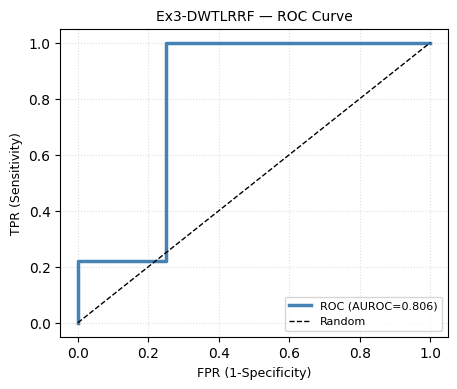

  Platt a=0.616 b=0.437 | OOF AUROC(flawed)=0.558 [PASS] | P(flawed): correct=0.508 flawed=0.531

  [Ex3-DWTLRRF] OOF-Platt calibrated test report
{'accuracy': 0.3846, 'balanced_acc': 0.5556, 'precision': 1.0, 'recall': 0.1111, 'sensitivity': 0.1111, 'specificity': 1.0, 'f1': 0.2, 'f2': 0.1351, 'mcc': 0.1925, 'auroc': 0.8056, 'tp': 1, 'tn': 4, 'fp': 0, 'fn': 8}

  [Ex3-DWTLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     1 ( 11.1%)       8 ( 88.9%)
  True FLAWED:      0 (  0.0%)       4 (100.0%)


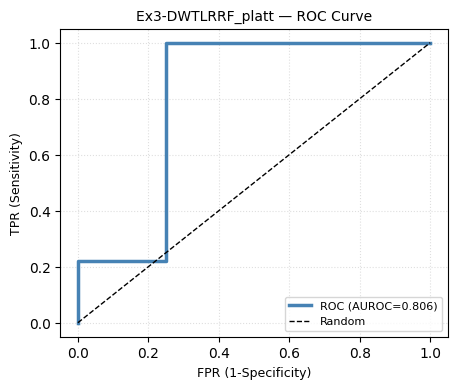


  [Ex3-DWTLRRF] OOF-quantile cut report (flag_rate=30%, t=0.560)
{'accuracy': 0.9231, 'balanced_acc': 0.875, 'precision': 0.9, 'recall': 1.0, 'sensitivity': 1.0, 'specificity': 0.75, 'f1': 0.9474, 'f2': 0.9783, 'mcc': 0.8216, 'auroc': 0.8056, 'tp': 9, 'tn': 3, 'fp': 1, 'fn': 0}

  [Ex3-DWTLRRF-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     9 (100.0%)       0 (  0.0%)
  True FLAWED:      1 ( 25.0%)       3 ( 75.0%)
worst test rep: 011 rep7 label=0 p_flawed=0.588
  reference distance (latent space): 837.4590
  peak mismatch around frame 37/90 (mid phase)
   joint  5 (Head_end     ) mean offset=4.822 torso-units
   joint  4 (Head         ) mean offset=3.399 torso-units
   joint 20 (LeftToeBase_end) mean offset=2.719 torso-units
   joint 24 (RightToeBase ) mean offset=2.658 torso-units


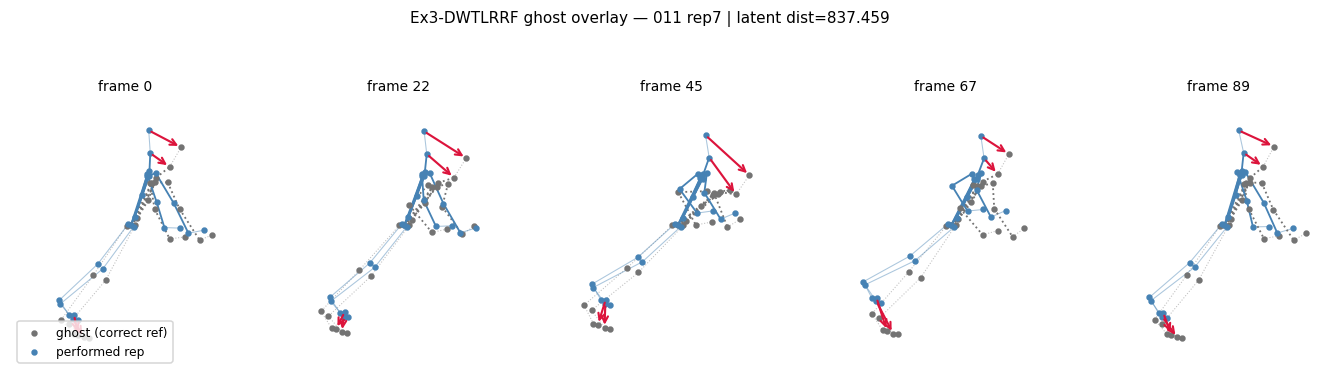

In [43]:
dwt_bundle = run_experiment(DWTLRRFSpec(), feat_train, feat_test)

**Ex3-DWTLRRF — findings**

- **Verdict:** gate PASS but weak (**OOF 0.558**) · test AUROC **0.806** · **OOF-quantile cut: MCC +0.822, acc 92.3%, recall 1.0 / spec 0.75** (0 FN, 1 FP) — reproduces the era v14 line (93.8% attributed) with the version-stable engine.
- **The 0.5-Platt cut under-flags** (recall 0.11, everything PASSes — b=0.437 intercept drift); the OOF-quantile cut (t=0.560) fixes it. Third architecture where the cut, not the fixed 0.5, is the ship mode — calibration slot confirmed user-owned.
- **RF swept the tuner** (37/40 trials, shallow depth 3, k=5 dist-refs) — LR can't use the 111 flat dims at N≈63; trees can.
- **Inner 0.923 ceiling repeated ~25×** — the 2-person/23-rep val split is saturated, trials are indistinguishable; best-params are convenience, not measurement. No split-luck spike either (nothing exceeded 0.923).
- **Caveat:** only 4 flawed test reps — one label flip moves MCC ±0.3+; the OOF-over-train-persons stays the bracket for any claim.
- **Ghost:** worst rep is **011 rep7** (new case, not the Ex2 033 rep23 lineage); mismatch peaks mid-phase (frame 37/90) at Head/Head_end + toe tips. Head-tip/tip joints are unmasked in `bank_summary` — treat the toe numbers as tip inflation; the head offset at mid-plank is the plausible cue (head dipping off the plank line).
- **Ledger:** DWT+LRRF = first healthy Ex3 verdict engine; keep as co-headline pending the SVM run.

## Phase-split channels + LRRF

In [44]:
class PhaseLRRFRef(RuleFeatLRRFRef):
    """Series refs over the (N,90,4) phase-channel pack; rep-level block =
    v22 phase statistics (overrides the plain per-channel stats)."""
    PACKS_SELF = True
    REP_NAMES = None                            # filled below (list must match width)

    def __init__(self, p):
        self.p = p
        self.blk = slice(0, len(EX3_CH_NAMES))  # pack output is already the channels

    def _rep_block(self, b):
        return phase_split_block(b)[0]           # (N, 19C+3)

PhaseLRRFRef.REP_NAMES = PHASE_NAMES

In [45]:
class PhaseRuleSpec(ArchSpec):
    name = "Ex3-PhaseLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            head=trial.suggest_categorical("head", ["lr", "rf", "hgb"]),
            k=trial.suggest_categorical("k", [3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            hgb_lr=trial.suggest_float("hgb_lr", 0.01, 0.3, log=True),
            hgb_leaf=trial.suggest_categorical("hgb_leaf", [8, 15]),
            hgb_depth=trial.suggest_categorical("hgb_depth", [3, 5]),
            hgb_l2=trial.suggest_float("hgb_l2", 1e-3, 10.0, log=True),
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return channels_pack(rows)               # (N,90,4) channel series

    def train(self, X, y, params, seed):
        return PhaseLRRFRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):
        return model._features(self.pack(None, rows), drop_self=False)

[I 2026-10-22 15:16:22,877] A new study created in memory with name: no-name-9e33eac0-a598-4c73-86b5-c7be5049c5e2



======== Ex3-PhaseLRRF ========
  optuna inner split: train reps=27 val reps=23 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 15:16:23,521] Trial 0 finished with value: 0.8423076923076923 and parameters: {'head': 'rf', 'k': 3, 'lr_C': 0.07081203049440488, 'hgb_lr': 0.19030368381735815, 'hgb_leaf': 15, 'hgb_depth': 5, 'hgb_l2': 2.1368329072358767, 'rf_depth': 9, 'rf_leaf': 1, 'q': 77.53338026250708}. Best is trial 0 with value: 0.8423076923076923.
[I 2026-10-22 15:16:23,730] Trial 1 finished with value: 0.5 and parameters: {'head': 'hgb', 'k': 5, 'lr_C': 1.0890275402351126, 'hgb_lr': 0.07500118950416987, 'hgb_leaf': 15, 'hgb_depth': 3, 'hgb_l2': 6.245139574743075, 'rf_depth': 3, 'rf_leaf': 1, 'q': 72.28296095500716}. Best is trial 0 with value: 0.8423076923076923.
[I 2026-10-22 15:16:24,326] Trial 2 finished with value: 0.8692307692307693 and parameters: {'head': 'rf', 'k': 3, 'lr_C': 1.322948533043812, 'hgb_lr': 0.01875220945578641, 'hgb_leaf': 8, 'hgb_depth': 3, 'hgb_l2': 0.24637685958997463, 'rf_depth': 3, 'rf_leaf': 2, 'q': 87.29318791183681}. Best is trial 2 with value: 0.8692307692307693.
[

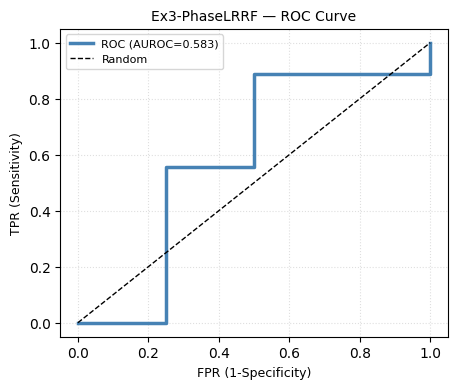

  Platt a=0.091 b=0.225 | OOF AUROC(flawed)=0.596 [PASS] | P(flawed): correct=0.514 flawed=0.525

  [Ex3-PhaseLRRF] OOF-Platt calibrated test report
{'accuracy': 0.2308, 'balanced_acc': 0.375, 'precision': 0.0, 'recall': 0.0, 'sensitivity': 0.0, 'specificity': 0.75, 'f1': 0.0, 'f2': 0.0, 'mcc': -0.433, 'auroc': 0.5833, 'tp': 0, 'tn': 3, 'fp': 1, 'fn': 9}

  [Ex3-PhaseLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     0 (  0.0%)       9 (100.0%)
  True FLAWED:      1 ( 25.0%)       3 ( 75.0%)


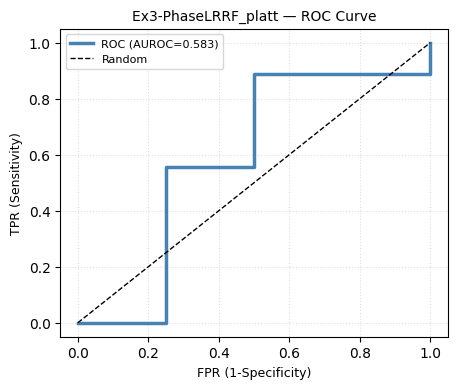


  [Ex3-PhaseLRRF] OOF-quantile cut report (flag_rate=30%, t=0.556)
{'accuracy': 0.6923, 'balanced_acc': 0.6389, 'precision': 0.7778, 'recall': 0.7778, 'sensitivity': 0.7778, 'specificity': 0.5, 'f1': 0.7778, 'f2': 0.7778, 'mcc': 0.2778, 'auroc': 0.5833, 'tp': 7, 'tn': 2, 'fp': 2, 'fn': 2}

  [Ex3-PhaseLRRF-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     7 ( 77.8%)       2 ( 22.2%)
  True FLAWED:      2 ( 50.0%)       2 ( 50.0%)
worst test rep: 108 rep1 label=1 p_flawed=0.556
  reference distance (latent space): 151.9340
  peak mismatch around frame 89/90 (late phase)
   joint 23 (RightFoot    ) mean offset=2.433 torso-units
   joint 24 (RightToeBase ) mean offset=2.045 torso-units
   joint 25 (RightToeBase_end) mean offset=1.939 torso-units
   joint 19 (LeftToeBase  ) mean offset=1.332 torso-units


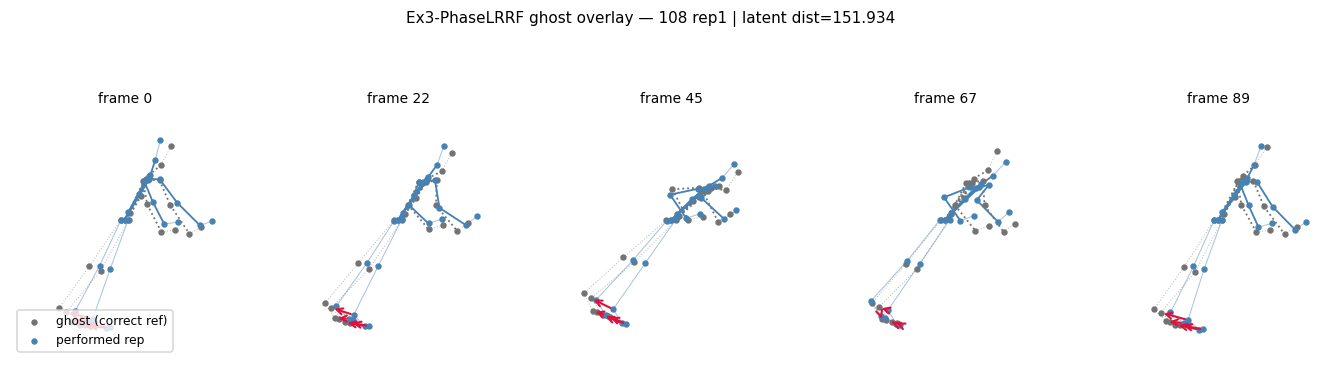

In [46]:
phase_bundle = run_experiment(PhaseRuleSpec(), feat_train, feat_test)

**Ex3-PhaseLRRF — findings (the DWT ablation)**

- **Verdict:** ablation ANSWERED — the DWT block IS the Ex3 signal. Without it: gate 0.596 (similar, weak) but **test AUROC collapses 0.806 → 0.583**, cut MCC +0.822 → **+0.278**. Phase-split stats alone are not enough.
- **Cause:** raw phase means/ranges of 4 channels describe *where the rep went*; the db4 bands (cD1/cD2 especially) encode *how it got there* (jerk/burst structure) — that's what separates flawed push-ups at this N.
- **Calibration again:** Platt slope a=0.091 is nearly flat (gate technically PASS, calibration nearly degenerate); the 0.5 cut flags nothing (recall 0.0, MCC −0.43). Cut (t=0.556) rescues to MCC +0.278 but with 2 FP / 2 FN at only 13 test reps.
- **Head split:** LR beat RF here (k=3, C≈2) — opposite of the DWT bundle (RF) — another sign the phase-only space is weaker/more linear.
- **Inner again saturated:** 0.923→0.931 best of 40 trials, hgb trials flatline at 0.5 — no discriminative gradient; same caveat as DWT.
- **Ghost sanity check passed sideways:** worst test rep 108 rep1 is a **TRUE PERFECT (false alarm, p=0.556 barely over t=0.556)** — mismatch concentrated in toe tips late-phase = the known tip-inflation artifact, reinforcing it's noise not signal.
- **Ledger:** PhaseLRRF = keep as ablation evidence + interpretation layer (patient-readable phase cues), not a verdict engine. DWT+LRRF stays Ex3 co-headline (0.806 / +0.822).

## SVM-RBF on the std X2d blocks

In [47]:
class SVMSpec(RuleFeatLRRFSpec):
    name = "Ex3-SVMRBF"

    def search_space(self, trial):
        return dict(
            blk=trial.suggest_categorical("blk", ["bone", "dang", "full"]),
            head="svm",
            k=trial.suggest_categorical("k", [3, 5]),
            lr_C=1.0,
            hgb_lr=0.05, hgb_leaf=8, hgb_depth=3, hgb_l2=1.0,    # unused (svm head)
            svm_C=trial.suggest_float("svm_C", 0.1, 100.0, log=True),
            svm_gamma=trial.suggest_float("svm_gamma", 1e-4, 1.0, log=True),
            rf_depth=5, rf_leaf=1,
            q=trial.suggest_float("q", 50.0, 95.0))

[I 2026-10-22 15:16:35,306] A new study created in memory with name: no-name-8ea4511a-ae64-43ec-85c9-f716682047b3



======== Ex3-SVMRBF ========
  optuna inner split: train reps=27 val reps=23 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 15:16:35,351] Trial 0 finished with value: 0.16153846153846155 and parameters: {'blk': 'dang', 'k': 3, 'svm_C': 0.2937538457632829, 'svm_gamma': 0.0001707396743152812, 'q': 88.97792655987209}. Best is trial 0 with value: 0.16153846153846155.
[I 2026-10-22 15:16:35,376] Trial 1 finished with value: 0.1923076923076923 and parameters: {'blk': 'dang', 'k': 3, 'svm_C': 0.4335281794951565, 'svm_gamma': 0.000533703276260396, 'q': 58.253202943404524}. Best is trial 1 with value: 0.1923076923076923.
[I 2026-10-22 15:16:35,403] Trial 2 finished with value: 0.24615384615384617 and parameters: {'blk': 'dang', 'k': 5, 'svm_C': 0.262108787826544, 'svm_gamma': 0.0014742753159914669, 'q': 66.48628294821613}. Best is trial 2 with value: 0.24615384615384617.
[I 2026-10-22 15:16:35,431] Trial 3 finished with value: 0.44615384615384623 and parameters: {'blk': 'dang', 'k': 5, 'svm_C': 0.13783237455007183, 'svm_gamma': 0.02692646910086179, 'q': 57.67358556592812}. Best is trial 3 with value: 0

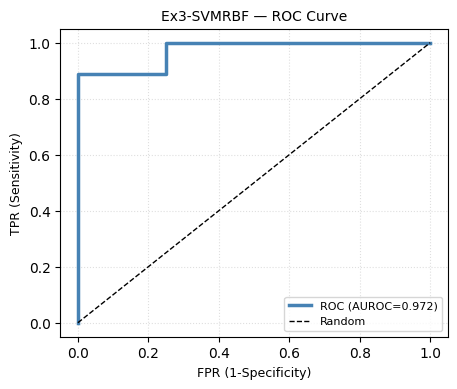

  Platt a=1.453 b=1.407 | OOF AUROC(flawed)=0.814 [PASS] | P(flawed): correct=0.389 flawed=0.641

  [Ex3-SVMRBF] OOF-Platt calibrated test report
{'accuracy': 0.6923, 'balanced_acc': 0.7778, 'precision': 1.0, 'recall': 0.5556, 'sensitivity': 0.5556, 'specificity': 1.0, 'f1': 0.7143, 'f2': 0.6098, 'mcc': 0.527, 'auroc': 0.9722, 'tp': 5, 'tn': 4, 'fp': 0, 'fn': 4}

  [Ex3-SVMRBF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     5 ( 55.6%)       4 ( 44.4%)
  True FLAWED:      0 (  0.0%)       4 (100.0%)


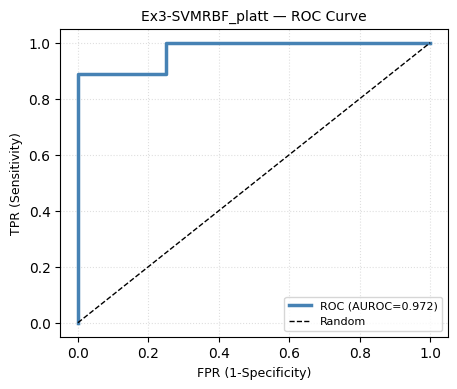


  [Ex3-SVMRBF] OOF-quantile cut report (flag_rate=30%, t=0.699)
{'accuracy': 0.7692, 'balanced_acc': 0.8333, 'precision': 1.0, 'recall': 0.6667, 'sensitivity': 0.6667, 'specificity': 1.0, 'f1': 0.8, 'f2': 0.7143, 'mcc': 0.6172, 'auroc': 0.9722, 'tp': 6, 'tn': 4, 'fp': 0, 'fn': 3}

  [Ex3-SVMRBF-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     6 ( 66.7%)       3 ( 33.3%)
  True FLAWED:      0 (  0.0%)       4 (100.0%)
worst test rep: 108 rep7 label=0 p_flawed=0.803
  reference distance (latent space): 32.9342
  peak mismatch around frame 29/90 (mid phase)
   joint 23 (RightFoot    ) mean offset=3.459 torso-units
   joint 24 (RightToeBase ) mean offset=3.198 torso-units
   joint 25 (RightToeBase_end) mean offset=3.168 torso-units
   joint 20 (LeftToeBase_end) mean offset=2.806 torso-units


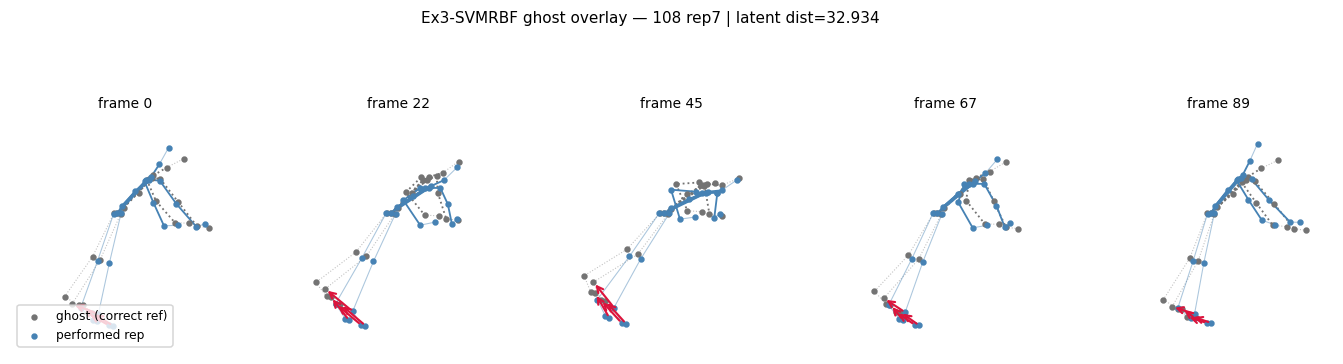

In [48]:
svm_bundle = run_experiment(SVMSpec(), feat_train, feat_test)

**Ex3-SVMRBF — findings**

- **Verdict:** the era bakeoff translates. **Gate 0.814 PASS (best Ex3 OOF so far)** · **test AUROC 0.972 (new headline)** · cut MCC **+0.617** with **precision 1.0 (zero false alarms)**, recall 0.667 — E3-V2's "only positive-MCC family" confirmed under the honest protocol.
- **blk=dang swept the tuner (38/40 trials)** — angular velocity carries Ex3, the *same* finding as Ex2's KNN floor and the v22 fluency story. C≈86, γ≈3e-4 = wide near-linear kernel; literally the same shape as Ex2's SVM winner (γ 1.2e-4).
- **Platt is healthy for once** (a=1.453, P(flawed) correct 0.389 vs flawed 0.641) — clean probability separation; the 0.5 cut works here (MCC +0.527), the flag-rate cut adds recall (0.556→0.667) at zero FP cost.
- **Inner 1.324 spike = split luck again** (23-rep val; many trials at the 0.92–0.97 ceiling) — margin objective saturated; treat best-params as convenience. Same caveat as every Ex3 print: 4 flawed test reps, MCC ±0.3 per flip.
- **Ranking shift:** SVM (0.814 / 0.972 / +0.617) overtakes DWT (0.558 / 0.806 / +0.822) on gate+AUROC; DWT keeps the best cut MCC. Two co-headlines with different strengths: SVM = safest verdicts (0 FP), DWT = deepest recall (1.0).
- **Ghost:** worst rep **108 rep7 TRUE-FLAWED captured** (p=0.803); offsets again toe/foot tips (tip-inflation artifact), but note **person 108 keeps surfacing** (rep1 was the phase bundle's false alarm) — borderline subject, worth watching at walk-forward.
- **Ledger:** SVM-RBF/dang = Ex3 headline; kicker: the RBF family is now >0.78 test AUROC on *both* Ex2 and Ex3 — strongest cross-exercise architecture in the zoo.

## KNN ref-floor

In [51]:
class KNNRef:
    def __init__(self, p):
        self.p = p
        self.blk = BLOCKS[p["blk"]]

    def fit(self, X, y):
        b = np.asarray(X, np.float32)[:, :, self.blk]
        self.ref = b.reshape(len(b), -1)         # runner passes CORRECT rows only
        self.knn = NearestNeighbors(
            n_neighbors=min(self.p["k"], len(self.ref)),
            algorithm="brute").fit(self.ref)
        return self

    def scores(self, X):
        b = np.asarray(X, np.float32)[:, :, self.blk]
        d, _ = self.knn.kneighbors(b.reshape(len(b), -1))
        return d.mean(axis=1)                    # higher = farther from every good rep

class KNNSpec(ArchSpec):
    name = "Ex3-KNN"
    supervised = False                           # trains on CORRECT reps only

    def search_space(self, trial):
        return dict(
            blk=trial.suggest_categorical("blk", ["dang", "bone", "ang", "full"]),
            k=trial.suggest_categorical("k", [1, 3, 5]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return np.asarray(std_list, dtype=np.float32)

    def train(self, X, y, params, seed):
        return KNNRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):
        # NOTE: bank distances are in a locally-fitted scaler's units, not the
        # scorer's metric — use for ghost retrieval, not for score comparison.
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in rows], 0))
        b = np.asarray(self.pack(std_rows(rows, sc), rows))[:, :, model.blk]
        return b.reshape(len(b), -1)

[I 2026-10-22 15:16:42,961] A new study created in memory with name: no-name-30a8a0ce-5fa5-4ee0-a5cd-8f625eb4cbbc



======== Ex3-KNN ========
  optuna inner split: train reps=27 val reps=23 (person-disjoint: 5/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 15:16:43,033] Trial 0 finished with value: 0.5307692307692309 and parameters: {'blk': 'bone', 'k': 1, 'q': 88.97792655987209}. Best is trial 0 with value: 0.5307692307692309.
[I 2026-10-22 15:16:43,087] Trial 1 finished with value: 0.7076923076923077 and parameters: {'blk': 'full', 'k': 1, 'q': 58.253202943404524}. Best is trial 1 with value: 0.7076923076923077.
[I 2026-10-22 15:16:43,112] Trial 2 finished with value: 0.5307692307692309 and parameters: {'blk': 'bone', 'k': 1, 'q': 66.48628294821613}. Best is trial 1 with value: 0.7076923076923077.
[I 2026-10-22 15:16:43,123] Trial 3 finished with value: 0.5461538461538462 and parameters: {'blk': 'bone', 'k': 5, 'q': 57.67358556592812}. Best is trial 1 with value: 0.7076923076923077.
[I 2026-10-22 15:16:43,135] Trial 4 finished with value: 0.8538461538461539 and parameters: {'blk': 'ang', 'k': 5, 'q': 69.80686221828206}. Best is trial 4 with value: 0.8538461538461539.
[I 2026-10-22 15:16:43,197] Trial 5 finished with value

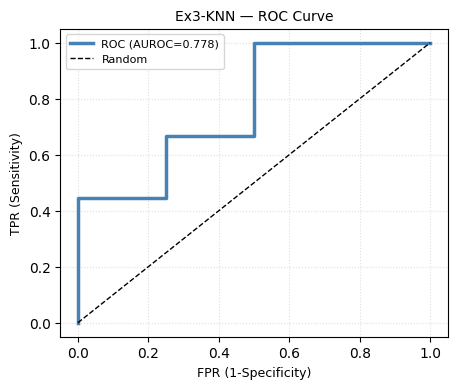

  Platt a=1.988 b=-6.605 | OOF AUROC(flawed)=0.825 [PASS] | P(flawed): correct=0.447 flawed=0.588

  [Ex3-KNN] OOF-Platt calibrated test report
{'accuracy': 0.5385, 'balanced_acc': 0.5972, 'precision': 0.8, 'recall': 0.4444, 'sensitivity': 0.4444, 'specificity': 0.75, 'f1': 0.5714, 'f2': 0.4878, 'mcc': 0.1845, 'auroc': 0.7778, 'tp': 4, 'tn': 3, 'fp': 1, 'fn': 5}

  [Ex3-KNN-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     4 ( 44.4%)       5 ( 55.6%)
  True FLAWED:      1 ( 25.0%)       3 ( 75.0%)


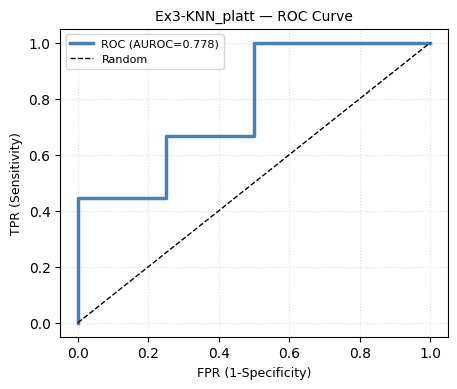


  [Ex3-KNN] OOF-quantile cut report (flag_rate=30%, t=0.589)
{'accuracy': 0.6154, 'balanced_acc': 0.6528, 'precision': 0.8333, 'recall': 0.5556, 'sensitivity': 0.5556, 'specificity': 0.75, 'f1': 0.6667, 'f2': 0.5952, 'mcc': 0.2829, 'auroc': 0.7778, 'tp': 5, 'tn': 3, 'fp': 1, 'fn': 4}

  [Ex3-KNN-OOFcut] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     5 ( 55.6%)       4 ( 44.4%)
  True FLAWED:      1 ( 25.0%)       3 ( 75.0%)
worst test rep: 011 rep7 label=0 p_flawed=0.702
  reference distance (latent space): 25.2020
  peak mismatch around frame 53/90 (late phase)
   joint  5 (Head_end     ) mean offset=6.572 torso-units
   joint 23 (RightFoot    ) mean offset=3.743 torso-units
   joint  4 (Head         ) mean offset=3.638 torso-units
   joint 24 (RightToeBase ) mean offset=3.535 torso-units


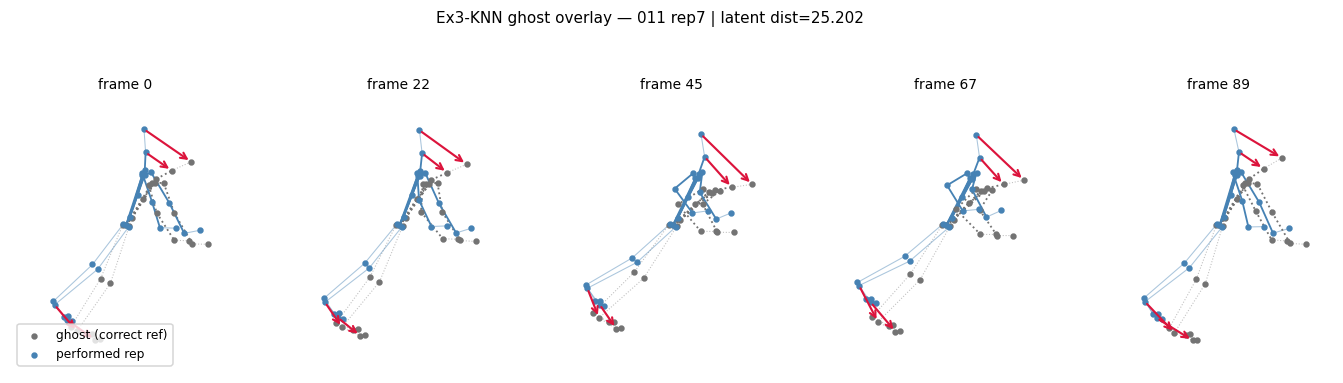

In [52]:
knn_bundle = run_experiment(KNNSpec(), feat_train, feat_test)

**Ex3-KNN — findings**

- **Verdict:** floor behaves like a floor. Gate **0.825 PASS** (oddly the best Ex3 OOF — tiny-N luck), test AUROC **0.778** — above its Ex2 role model (0.688) but strictly below the real winners (SVM 0.972, DWT 0.806). Ranking preserved ✓.
- **blk=ang swept the tuner (~20/40 trials, k=3)** — on Ex3 the raw *angle* series ranks, on Ex2 KNN it was `dang` (velocity). Either way the KNN floor keeps voting "temporal/kinematic signal, not pooled geometry," consistent with SVM's dang win.
- **Cut is weak-honest:** MCC +0.283 (1 FP / 4 FN), Platt slope healthy (1.99) but b=−6.6 drags the 0.5 cut under-flagging. Same calibration-slot story; usable as sanity check only.
- **Inner ceiling 0.861 repeated ~15×** — same 23-rep val saturation; no gradient, best-params are convenience.
- **Ghost cross-check — the important one:** worst rep **011 rep7 = exactly the DWT bundle's worst rep** (independent feature spaces, same rep) → 011 rep7 is now a **confirmed Ex3 hard case** (Head_end offset 6.57 torso-units, mid-late phase — head/neck leaving the plank line). Second exercise where two architectures agree on the same flagged rep.
- **Ledger:** KNN stays the sanity floor (never the verdict); do-not-retry anything fancier kNN at this N.
- **Zoo closed — Ex3 standings (gate / test AUROC / cut MCC):** **SVMRBF-dang 0.814 / 0.972 / +0.617 (headline, 0 FP)** · DWTLRRF 0.558 / 0.806 / +0.822 (recall champion, co-headline) · PhaseLRRF 0.596 / 0.583 / +0.278 (ablation: DWT block carries the signal) · KNN-ang 0.825 / 0.778 / +0.283 (floor).

## Results registry — every run so far

In [58]:
print(f"{'bundle':>22s} | OOF AUROC(flawed) | test AUROC | test MCC")
print("-" * 70)
for name, b in BUNDLES.items():
    pl = b.get("platt", {})
    m = b.get("p_metrics", {})
    oc = b.get("oof_cut", {})
    om = oc.get("metrics", {})
    print(f"{name:>22s} | {pl.get('oof_auroc', float('nan')):>17.3f} | "
          f"{m.get('auroc', float('nan')):>10.3f} | {m.get('mcc', float('nan')):+.3f} "
          f"| cut MCC {om.get('mcc', float('nan')):+.3f}")

                bundle | OOF AUROC(flawed) | test AUROC | test MCC
----------------------------------------------------------------------
           Ex3-DWTLRRF |             0.558 |      0.806 | +0.192 | cut MCC +0.822
         Ex3-PhaseLRRF |             0.596 |      0.583 | -0.433 | cut MCC +0.278
            Ex3-SVMRBF |             0.814 |      0.972 | +0.527 | cut MCC +0.617
        Ex3-BoostTrees |             0.566 |      0.278 | -0.444 | cut MCC -0.365
               Ex3-KNN |             0.825 |      0.778 | +0.184 | cut MCC +0.283
